In [68]:
# Imported Sionna and the functions we will use
# Imported the NumPy library for mathematical operations
import sionna.rt
import mitsuba as mi
from sionna.rt import (
    PlanarArray,
    Transmitter,
    Receiver,
    load_scene,
    PathSolver,
    SceneObject,
    ITURadioMaterial
    )
import numpy as np
import matplotlib.pyplot as plt

In [69]:
# Called our environment and loaded the scene
scene = load_scene()

#Does higher frequency increase RSS when an obstacle is present?

In [70]:
# Set our frequency to 3.5 GHz and change it to 7 GHz
#and the other parameters
scene.frequency = 7e9
tx_power_dbm = 30
c = 299792458.0
r = 20

In [71]:
# Using the PlanarArray function, we defined the number of Tx antenna elements, to be used as our base station, antenna properties and orientation

scene.tx_array= PlanarArray(
    num_rows=1, 
    num_cols=1,
    pattern="iso", 
    polarization="V",)

In [72]:
# We defined the properties of our receiving antenna
scene.rx_array= PlanarArray(
    num_rows=1,
    num_cols=1,
    pattern="iso",
    polarization="V",
)

In [73]:
# Named our transmitter Base Station 1 and defined its position
bs = Transmitter(
    name="BS1",
    position=[0, 0, 0]
)

In [74]:
# Added our base station to the scene
scene.add(bs)

In [75]:
# Named our first receiver and set its position at a distance of r from the base station
rx1 = Receiver(
    name="RX1",
    position=[r, 0, 0]
)

In [76]:
# Named our second receiver and set its position at a distance of 2*r from the base station# Named our second receiver and set its position at a distance of 2*r from the base station
rx2 = Receiver(
    name="RX2",
    position=[2*r, 0, 0]
)

In [77]:
# Named our third receiver and set its position at a distance of 3*r from the base station
rx3 = Receiver(
    name="RX3",
    position=[3*r, 0, 0]
)

In [78]:
# Named our fourth receiver and set its position at a distance of 10*r from the base station
rx4 = Receiver(
    name="RX4",
    position=[10*r, 0, 0]
)

In [79]:
# Added our receivers to the scene
scene.add(rx1)
scene.add(rx2)
scene.add(rx3)
scene.add(rx4)

In [80]:
# Printed the position of each receiver to make sure their positions were correct
for name in ["RX1", "RX2", "RX3", "RX4"]:
    rx = scene.get(name)
    print(name, np.array(rx.position))

RX1 [[20.]
 [ 0.]
 [ 0.]]
RX2 [[40.]
 [ 0.]
 [ 0.]]
RX3 [[60.]
 [ 0.]
 [ 0.]]
RX4 [[200.]
 [  0.]
 [  0.]]


In [81]:
# Defined the constant speed of light, wavelength, and base station power
# Calculated the free space path loss values for each receiver
# path gain = - path loss
# Calculated the received signal strength (RSS) for each receiver
c= 299792458.0
wavelength = c/ scene.frequency
bs_power_dbm = 30
fspl1 = 20*np.log10(4*np.pi*rx1.position[0]/wavelength)
fspl2 = 20*np.log10(4*np.pi*rx2.position[0]/wavelength)
fspl3 = 20*np.log10(4*np.pi*rx3.position[0]/wavelength)
fspl4 = 20*np.log10(4*np.pi*rx4.position[0]/wavelength)

rss1 = bs_power_dbm - fspl1
rss2 = bs_power_dbm - fspl2
rss3 = bs_power_dbm - fspl3
rss4 = bs_power_dbm - fspl4

print(f"RSS at RX1: {rss1} dBm")
print(f"RSS at RX2: {rss2} dBm")
print(f"RSS at RX3: {rss3} dBm")
print(f"RSS at RX4: {rss4} dBm")

print(f"FSPL at RX1: {fspl1} dB")
print(f"FSPL at RX2: {fspl2} dB")
print(f"FSPL at RX3: {fspl3} dB")
print(f"FSPL at RX4: {fspl4} dB")

# Convert received power from dBm to nanowatts for comparing
p_rx1 = 10**((rss1 - 30) / 10) * 1e9
p_rx2 = 10**((rss2 - 30) / 10) * 1e9
p_rx3 = 10**((rss3 - 30) / 10) * 1e9
p_rx4 = 10**((rss4 - 30) / 10) * 1e9

print(f"RX1: {p_rx1.item():.2f} nW")
print(f"RX2: {p_rx2.item():.2f} nW")
print(f"RX3: {p_rx3.item():.2f} nW")
print(f"RX4: {p_rx4.item():.2f} nW")

print(f"RX2 / RX1: {((p_rx2 / p_rx1).item()):.2f}")

RSS at RX1: [-45.370346] dBm
RSS at RX2: [-51.390945] dBm
RSS at RX3: [-54.912766] dBm
RSS at RX4: [-65.37034] dBm
FSPL at RX1: [75.370346] dB
FSPL at RX2: [81.390945] dB
FSPL at RX3: [84.912766] dB
FSPL at RX4: [95.37034] dB
RX1: 29.04 nW
RX2: 7.26 nW
RX3: 3.23 nW
RX4: 0.29 nW
RX2 / RX1: 0.25


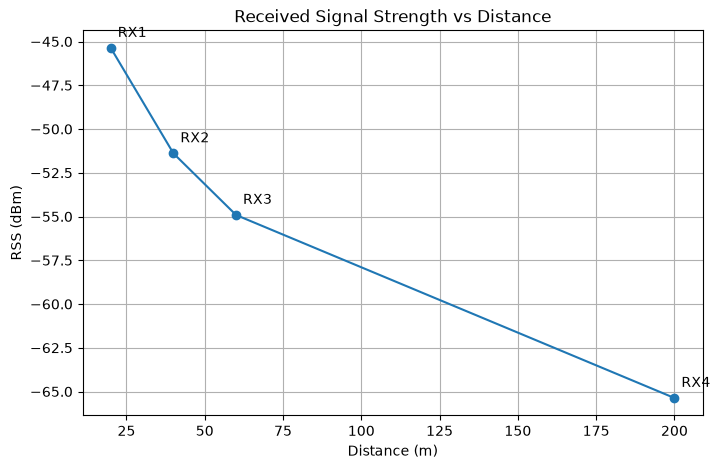

In [82]:
# Receiver distances (meters)
distances = [r, 2*r, 3*r, 10*r]

# Received signal strength values (dBm)
rss_values = [
    np.asarray(rss1).item(),
    np.asarray(rss2).item(),
    np.asarray(rss3).item(),
    np.asarray(rss4).item()
]

# Plot RSS vs Distance
plt.figure(figsize=(8, 5))

plt.plot(distances, rss_values, marker="o", linestyle="-")

# Add receiver labels
for i in range(4):
    plt.annotate(
        f"RX{i+1}",
        (distances[i], rss_values[i]),
        xytext=(5, 8),
        textcoords="offset points"
    )

plt.xlabel("Distance (m)")
plt.ylabel("RSS (dBm)")
plt.title("Received Signal Strength vs Distance")
plt.grid(True)

plt.show()

In [83]:
# Create a building geometry using Mitsuba
building_mesh = mi.load_dict({
    "type": "cube",
    "to_world": mi.ScalarTransform4f()
        .translate([30, 0, -4])
        .scale([5, 5, 7.5])
})

print(type(building_mesh))

<class 'mitsuba.Mesh'>


In [84]:
# Create a Sionna scene object from the Mitsuba mesh
building1 = SceneObject(
    mi_mesh=building_mesh,
    name="building1",
    radio_material=ITURadioMaterial(
        name="concrete",
        itu_type="concrete"
    )
)

In [85]:
# Add the building to the scene
scene.add(building1)

In [86]:
scene.preview()

In [87]:
solver = PathSolver()

paths_with = solver(
    scene,
    max_depth=3,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    diffraction= False
)

In [88]:
# Remove the building
scene.remove("building1")

# Calculate propagation paths without the building
paths_without = solver(
    scene,
    max_depth=3,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    diffraction=False
)

In [89]:
#if obsticle in between rss ve path gain value changing
# Get channel coefficients

# Calculate path gain and RSS from channel coefficients
def calculate_rss(paths, tx_power_dbm=30):

    a_real, a_imag = paths.a
    a = np.array(a_real) + 1j * np.array(a_imag)

    # Combine propagation paths coherently
    h = np.sum(a, axis=-1)

    # Calculate path gain
    path_gain = np.abs(h)**2
    path_gain_db = 10 * np.log10(path_gain)

    # Calculate received signal strength
    rss_dbm = tx_power_dbm + path_gain_db

    return path_gain_db.reshape(-1), rss_dbm.reshape(-1)

In [90]:
# With building
gain_with, rss_with = calculate_rss(paths_with)

# Without building
gain_without, rss_without = calculate_rss(paths_without)

# Compare results
for i in range(4):
    print(f"RX{i+1}")
    print(f"RSS without building: {rss_without[i]:.2f} dBm")
    print(f"RSS with building:    {rss_with[i]:.2f} dBm")
    print(f"RSS difference:       {rss_with[i] - rss_without[i]:.2f} dB")
    print()

RX1
RSS without building: -45.37 dBm
RSS with building:    -48.02 dBm
RSS difference:       -2.65 dB

RX2
RSS without building: -51.39 dBm
RSS with building:    -84.53 dBm
RSS difference:       -33.14 dB

RX3
RSS without building: -54.91 dBm
RSS with building:    -86.09 dBm
RSS difference:       -31.18 dB

RX4
RSS without building: -65.37 dBm
RSS with building:    -98.51 dBm
RSS difference:       -33.14 dB



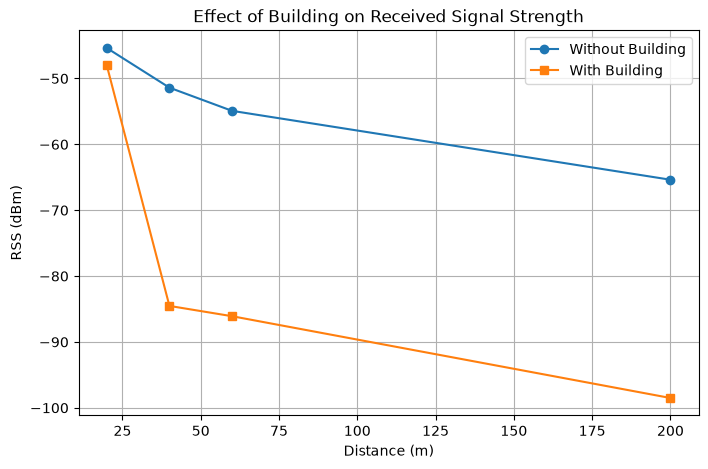

In [91]:
plt.figure(figsize=(8, 5))

plt.plot(distances, rss_without, marker="o", label="Without Building")
plt.plot(distances, rss_with, marker="s", label="With Building")

plt.xlabel("Distance (m)")
plt.ylabel("RSS (dBm)")
plt.title("Effect of Building on Received Signal Strength")
plt.legend()
plt.grid(True)
plt.show()

Research Question 3: What Happens When Only LoS Is Considered?

In [92]:
# Add the concrete building back to the scene
#scene.add(building1)

paths_los = solver(
    scene,
    max_depth=3,
    los=True,
    specular_reflection=False,
    diffuse_reflection=False,
    diffraction=False
)

gain_los, rss_los = calculate_rss(paths_los)

scene.remove("building1")
print(f"RX2 RSS (LoS only): {rss_los[1]:.2f} dBm")

RX2 RSS (LoS only): -51.39 dBm


Research Question 4: How Does Diffraction Affect RSS?

In [93]:
# Calculate paths with diffraction enabled
paths_diff = solver(
    scene,
    max_depth=3,
    los=True,
    specular_reflection=False,
    diffuse_reflection=False,
    diffraction=True
)

# Calculate paths with diffraction disabled
paths_no_diff = solver(
    scene,
    max_depth=3,
    los=True,
    specular_reflection=False,
    diffuse_reflection=False,
    diffraction=False
)

# Calculate RSS
gain_diff, rss_diff = calculate_rss(paths_diff)
gain_no_diff, rss_no_diff = calculate_rss(paths_no_diff)

# Compare
for i in range(4):
    print(f"RX{i+1}")
    print(f"With diffraction:    {rss_diff[i]:.6f} dBm")
    print(f"Without diffraction: {rss_no_diff[i]:.6f} dBm")
    print()

RX1
With diffraction:    -45.370346 dBm
Without diffraction: -45.370346 dBm

RX2
With diffraction:    -51.390945 dBm
Without diffraction: -51.390945 dBm

RX3
With diffraction:    -54.912766 dBm
Without diffraction: -54.912766 dBm

RX4
With diffraction:    -65.370338 dBm
Without diffraction: -65.370338 dBm



#Can diffraction occur around a perfectly shaped obstacle?
#hypothesis: if  there is no crack or sharp edge then no

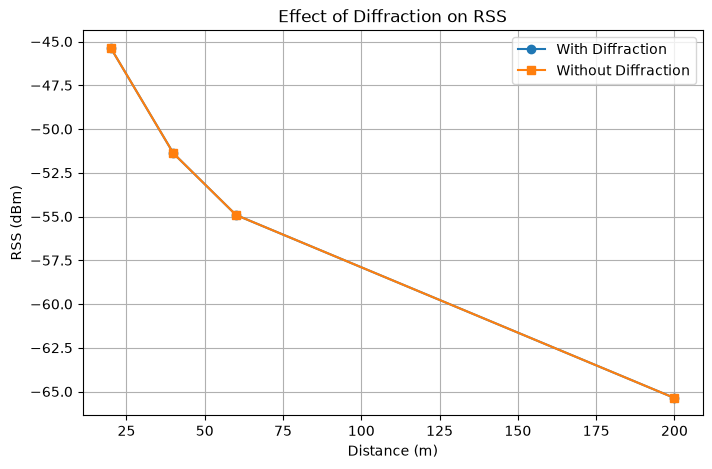

In [94]:
plt.figure(figsize=(8, 5))

plt.plot(distances, rss_diff, marker="o", label="With Diffraction")
plt.plot(distances, rss_no_diff, marker="s", label="Without Diffraction")

plt.xlabel("Distance (m)")
plt.ylabel("RSS (dBm)")
plt.title("Effect of Diffraction on RSS")
plt.legend()
plt.grid(True)
plt.show()

Research Question 5: Which Materials Affect Signal Propagation More?

#if we make this code block we can choose the material specifically
# Remove the concrete building from the scene
scene.remove("building3")
# Select the material manually
selected_material = "concrete"  # concrete, glass, brick, wood, metal

# Remove the previous building if it exists
if scene.get("building3") is not None:
    scene.remove("building3")

# Add building to scene
scene.add(building3)

# Calculate propagation paths
paths_material = solver(
    scene,
    max_depth=3,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    diffraction=False
)

# Calculate RSS and path gain
gain_material, rss_material = calculate_rss(paths_material)

# Print results
print(f"\nMaterial: {selected_material.upper()}")

for i in range(4):
    print(f"RX{i+1}")
    print(f"  RSS:       {rss_material[i]:.2f} dBm")
    print(f"  Path Gain: {gain_material[i]:.2f} dB")

In [95]:
# Research Question 5: Which materials affect signal propagation more?

# Remove the concrete building from the scene
scene.remove("building1")

# Materials to compare
materials = ["concrete", "glass", "brick", "wood"]
material_results = {}

for material_name in materials:

    # Create a building with the selected material
    building3 = SceneObject(
        mi_mesh=building_mesh,
        name="building3",
        radio_material=ITURadioMaterial(
            name=f"material_{material_name}",
            itu_type=material_name
        )
    )

    scene.add(building3)

    # Calculate propagation paths
    paths = solver(
        scene,
        max_depth=3,
        los=True,
        specular_reflection=True,
        diffuse_reflection=False,
        diffraction=False
    )

    # Calculate RSS and path gain
    gain, rss = calculate_rss(paths)

    material_results[material_name] = {
        "gain": gain.copy(),
        "rss": rss.copy()
    }

    # Print results
    print(f"\nMaterial: {material_name.upper()}")

    for i in range(4):
        print(f"RX{i+1}")
        print(f"  RSS:       {rss[i]:.2f} dBm")
        print(f"  Path Gain: {gain[i]:.2f} dB")

    # Remove building before testing the next material
    scene.remove("building3")


Material: CONCRETE
RX1
  RSS:       -48.02 dBm
  Path Gain: -78.02 dB
RX2
  RSS:       -84.53 dBm
  Path Gain: -114.53 dB
RX3
  RSS:       -86.09 dBm
  Path Gain: -116.09 dB
RX4
  RSS:       -98.51 dBm
  Path Gain: -128.51 dB

Material: GLASS
RX1
  RSS:       -48.59 dBm
  Path Gain: -78.59 dB
RX2
  RSS:       -61.53 dBm
  Path Gain: -91.53 dB
RX3
  RSS:       -63.47 dBm
  Path Gain: -93.47 dB
RX4
  RSS:       -75.51 dBm
  Path Gain: -105.51 dB

Material: BRICK
RX1
  RSS:       -47.76 dBm
  Path Gain: -77.76 dB
RX2
  RSS:       -58.71 dBm
  Path Gain: -88.71 dB
RX3
  RSS:       -65.32 dBm
  Path Gain: -95.32 dB
RX4
  RSS:       -72.69 dBm
  Path Gain: -102.69 dB

Material: WOOD
RX1
  RSS:       -46.52 dBm
  Path Gain: -76.52 dB
RX2
  RSS:       -60.82 dBm
  Path Gain: -90.82 dB
RX3
  RSS:       -62.59 dBm
  Path Gain: -92.59 dB
RX4
  RSS:       -74.80 dBm
  Path Gain: -104.80 dB


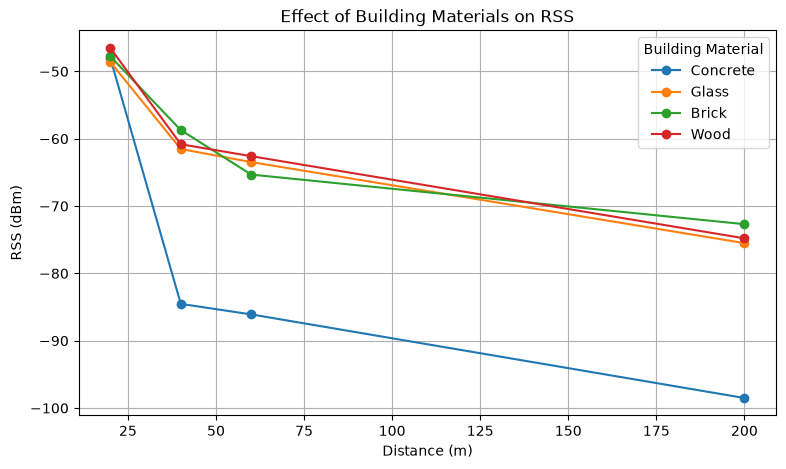

In [96]:
#Which reflecting materials affect propagation most?
#Material Comparison
plt.figure(figsize=(9, 5))

for material_name, results in material_results.items():
    plt.plot(
        distances,
        results["rss"],
        marker="o",
        label=material_name.capitalize()
    )

plt.xlabel("Distance (m)")
plt.ylabel("RSS (dBm)")
plt.title("Effect of Building Materials on RSS")
plt.legend(title="Building Material")
plt.grid(True)
plt.show()

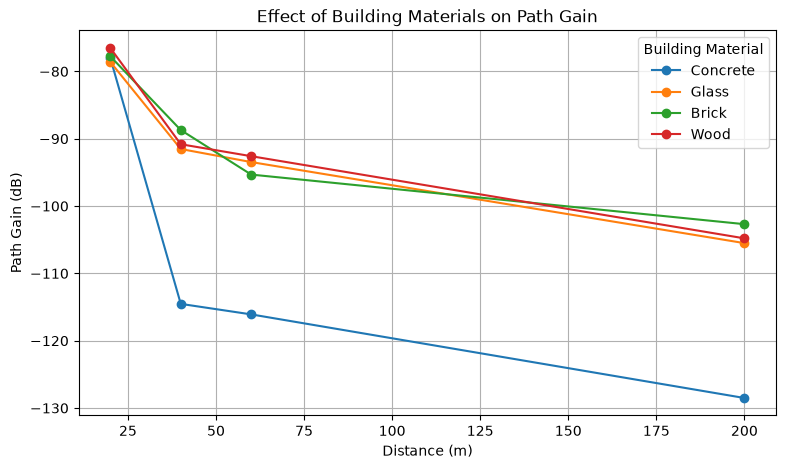

In [97]:
# path gain comparison
plt.figure(figsize=(9, 5))

for material_name, results in material_results.items():
    plt.plot(
        distances,
        results["gain"],
        marker="o",
        label=material_name.capitalize()
    )

plt.xlabel("Distance (m)")
plt.ylabel("Path Gain (dB)")
plt.title("Effect of Building Materials on Path Gain")
plt.legend(title="Building Material")
plt.grid(True)
plt.show()

#How do the received signal strength and path gain change with distance?
#My hypothesis: As distance increases, RSS decreases because path loss increases; path gain also decreases.

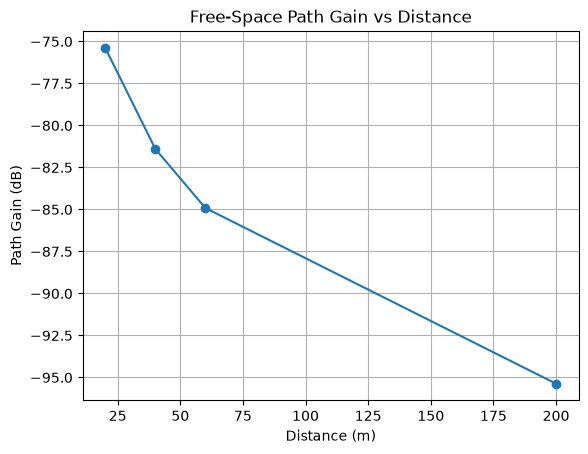

In [98]:
# Additional visualization: free-space path gain vs distance
free_space_gain = [
    -np.asarray(fspl1).item(),
    -np.asarray(fspl2).item(),
    -np.asarray(fspl3).item(),
    -np.asarray(fspl4).item()
]
plt.plot(distances, free_space_gain, marker="o")
plt.xlabel("Distance (m)")
plt.ylabel("Path Gain (dB)")
plt.title("Free-Space Path Gain vs Distance")
plt.grid(True)
plt.show()

#Does an object behind RX change its RSS?
# hypothesis: Binadan yansıyan sinyalin fazı farklıysa destructive interference olabilir; RSS azalabilir.

RX1 LoS-only RSS: -45.37 dBm
RX1 with specular paths: -48.02 dBm
Difference: -2.65 dB


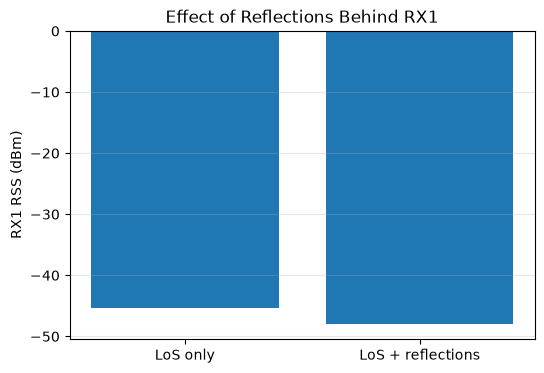

In [99]:
# RX1 is in front of the building: isolate reflection/interference effect
print(f"RX1 LoS-only RSS: {rss_los[0]:.2f} dBm")
print(f"RX1 with specular paths: {rss_with[0]:.2f} dBm")
print(f"Difference: {rss_with[0] - rss_los[0]:.2f} dB")
plt.figure(figsize=(6, 4))
plt.bar(["LoS only", "LoS + reflections"], [rss_los[0], rss_with[0]])
plt.ylabel("RX1 RSS (dBm)")
plt.title("Effect of Reflections Behind RX1")
plt.grid(axis="y", alpha=0.3)
plt.show()

#Can two locations at similar distances have different received signal strengths?

In [100]:
# Add RX5 at the same distance as RX1
rx5 = Receiver(
    name="RX5",
    position=[0, r, 0]
)
scene.add(rx5)

# Add the concrete building back to the scene
if scene.get("building1") is None:
    scene.add(building1)

# Calculate propagation paths
paths = solver(
    scene,
    max_depth=3,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    diffraction=False
)

gain, rss = calculate_rss(paths)

# Compare RX1 and RX5
print(f"RX1 RSS: {rss[0]:.2f} dBm")
print(f"RX5 RSS: {rss[4]:.2f} dBm")
print(f"Difference: {rss[4] - rss[0]:.2f} dB")

RX1 RSS: -46.52 dBm
RX5 RSS: -45.37 dBm
Difference: 1.15 dB


In [102]:
# Remove RX5 after the experiment
scene.remove("RX5")